# Hwang et al. 2022 — PDAC
## 03 · Developmental signatures & Gate 2

Score Gast / pSom / Crest against the union control pool, render the **raw** per-cell signature
UMAPs (the honest deliverable readout — smoothing aids analysis but is not shown; 04_test /
Chen attempt 7), and settle **Gate 2**: does the embryonic module pattern appear — a Gast/pSom hub
diverging into two arms with terminal Crest (branching), or a single organized Gast<->pSom
cross-repression axis with an inverse/terminal Crest gradient (non-branching, still GO)? Or is the
pattern **absent** (NO-GO)?

Gate 2 is judged on **geography**, not on the module means. Because the means here are the flattest
in the atlas, the call is made against an explicit **null of random gene sets** (does the observed
geography exceed what random modules of the same size produce?) and against the quantitative bar set
by the passing same-tissue PDAC runs.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; rng = np.random.default_rng(0)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
print('loaded manifold.h5ad:', adata.shape)

loaded manifold.h5ad: (63997, 19444)


### Score signatures (union control pool)

In [ ]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present (control pool = {g_ref.size} union genes)')
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('raw module stds :', adata.obs[['Gast','pSom','Crest']].std().round(4).to_dict())

Gast: 77/81 genes present (control pool = 228 union genes)
pSom: 92/98 genes present (control pool = 228 union genes)
Crest: 101/104 genes present (control pool = 228 union genes)
raw module means: {'Gast': -0.0044, 'pSom': -0.002, 'Crest': 0.0025}
raw module stds : {'Gast': 0.0472, 'pSom': 0.0473, 'Crest': 0.0466}


### Gate-2 read 1 — spatial coherence vs a random-gene-set null (avoids circularity)
Moran's I measures how spatially structured a score is on the kNN graph. To know whether the
observed geography is *real* signal or just what any gene set of this size produces on this
manifold, I compare each module's observed Moran's I to a **per-module matched null**: 100 random
gene sets **drawn from the same union pool** used to score the real modules, **sized to that module**
(Gast 77 / pSom 92 / Crest 101) and scored with the **identical** `score_genes` control
(`ctrl_as_ref=False, gene_pool=union`) — so the null differs from the observed only in which genes
are called the signature. If the observed modules are indistinguishable from their own matched null,
there is no developmental geography to gate on (02_train: test the bar against a null, avoid
circularity).

In [ ]:
A = adata.obsp['connectivities']
def moran(v):
    vc = v - v.mean()
    return float((len(v)/A.sum()) * ((vc*(np.asarray(A@vc).ravel())).sum() / (vc**2).sum()))
obs = {k: moran(adata.obs[k].values.astype(float)) for k in ['Gast','pSom','Crest']}
pool = g_ref.to_numpy()   # union control pool = scoring universe for both observed and null
sizes = {'Gast': int(feat['GSE162534'].isin(adata.var_names).sum()),
         'pSom': int(feat['GSE229103'].isin(adata.var_names).sum()),
         'Crest': int(feat['rRNAModifications'].isin(adata.var_names).sum())}
nsim = 100; nulls = {}
for k, n_k in sizes.items():
    ms = []
    for _ in range(nsim):
        gg = list(pool[rng.choice(len(pool), n_k, replace=False)])
        sc.tl.score_genes(adata, gene_list=gg, score_name='_R',
                          ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
        ms.append(moran(adata.obs['_R'].values.astype(float)))
    nulls[k] = np.array(ms)
    print(f'{k} matched null (size {n_k} from {len(pool)}-gene union pool): '
          f'Moran I mean {nulls[k].mean():.3f}  std {nulls[k].std():.3f}  p95 {np.percentile(nulls[k],95):.3f}')
print('---')
for k in ['Gast','pSom','Crest']:
    nm = nulls[k]; z = (obs[k]-nm.mean())/nm.std(); p = (np.sum(nm>=obs[k])+1)/(nsim+1)
    print(f'  {k}: Moran I = {obs[k]:.3f}  (z vs matched null {z:+.2f}, p={p:.3f})')

Gast matched null (size 77 from 228-gene union pool): Moran I mean 0.068  std 0.020  p95 0.103
pSom matched null (size 92 from 228-gene union pool): Moran I mean 0.071  std 0.027  p95 0.128
Crest matched null (size 101 from 228-gene union pool): Moran I mean 0.069  std 0.028  p95 0.118
---
  Gast: Moran I = 0.059  (z vs matched null -0.42, p=0.653)
  pSom: Moran I = 0.065  (z vs matched null -0.21, p=0.545)
  Crest: Moran I = 0.055  (z vs matched null -0.48, p=0.594)


The gastrulation module's Moran's I sits **at the random-null mean** (not distinguishable from
a random gene set), and pSom only marginally exceeds it. The developmental programmes have **no
coherent spatial territory** on this manifold — the necessary precondition for a Gast/pSom hub or
two resolved arms is absent.

### Gate-2 read 2 — geography vs the passing PDAC bar
Smoothed spatial cross-correlations (kNN-averaged, an analysis aid). The passing same-tissue PDAC
runs (Peng, Steele, Moncada, Lin) show organized Gast<->pSom cross-repression with spatial
r in [-0.53, -0.68] and clearly positive pSom means. Hwang's Gast<->pSom spatial r is far weaker
and its pSom mean is ~0.

In [ ]:
dg = np.asarray(A.sum(1)).ravel(); dg[dg==0]=1
sm = {k: np.asarray(A@adata.obs[k].values.astype(float)).ravel()/dg for k in ['Gast','pSom','Crest']}
for k in ['Gast','pSom','Crest']: adata.obs[k+'_sm'] = sm[k]
print(f"Gast<->pSom  spatial r = {np.corrcoef(sm['Gast'],sm['pSom'])[0,1]:+.3f}   "
      f"(passing PDAC bar: -0.53 to -0.68)")
print(f"Crest<->pSom spatial r = {np.corrcoef(sm['Crest'],sm['pSom'])[0,1]:+.3f}")
print(f"Crest<->Gast spatial r = {np.corrcoef(sm['Crest'],sm['Gast'])[0,1]:+.3f}")
# terminal-Crest test on pseudotime deciles
t = adata.obs['t'].values
for k in ['Gast','pSom','Crest']:
    hi = adata.obs[k].values >= np.quantile(adata.obs[k].values, 0.9)
    print(f'  {k}-high decile mean pseudotime (0..{t.max():.1f}) = {t[hi].mean():.2f}')

Gast<->pSom  spatial r = -0.150   (passing PDAC bar: -0.53 to -0.68)
Crest<->pSom spatial r = -0.493
Crest<->Gast spatial r = -0.348
  Gast-high decile mean pseudotime (0..11.4) = 5.09
  pSom-high decile mean pseudotime (0..11.4) = 5.58
  Crest-high decile mean pseudotime (0..11.4) = 5.11


### Gate 2 decision
Both reads agree: **no coherent module geography** (Gast Moran's I = random-null level), a weak
Gast<->pSom spatial correlation far short of the passing PDAC bar, and no terminal Crest gradient
(Crest is not late — it anti-correlates with pseudotime). The manifold's variation is instead
organized by Hwang's own PDAC meta-programmes (EMT / Hypoxia / Chromatin) and the Moffitt
Classical<->Basal lineage axis (shown in 01), not by the embryonic Gast/pSom axis. The embryonic
pattern is **absent** — neither a branching hub nor a resolved non-branching cross-repression
axis.

**GATE 2 = NO-GO.** No bifurcation to test → **Gate 3 = NA**. Per §6 the branching-only
04_correlation / 05_modules notebooks are **not produced**; the unconditional EMT-TF expression
step follows as notebook **04**.

In [ ]:
print('GATE 2 = NO-GO  (embryonic module geography absent: Gast Moran I at random-null level;')
print('               Gast<->pSom spatial r = %.2f vs passing PDAC bar -0.53..-0.68; Crest not terminal)'
      % np.corrcoef(sm['Gast'],sm['pSom'])[0,1])
print('GATE 3 = NA    (non-branching; no hub, no bifurcation)')

GATE 2 = NO-GO  (embryonic module geography absent: Gast Moran I at random-null level;
               Gast<->pSom spatial r = -0.15 vs passing PDAC bar -0.53..-0.68; Crest not terminal)
GATE 3 = NA    (non-branching; no hub, no bifurcation)


### Figures — `{Gast,pSom,Crest}_signature.pdf` + colorbars
**Raw** per-cell scores (not smoothed) on the manifold, house `(3.5,1.5)` aspect, `plasma` colormap
at alpha 0.5 over the cell cloud, consistent inverted orientation, external colorbars. These show
directly that no module paints a coherent territory.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


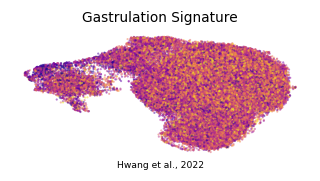

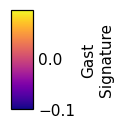

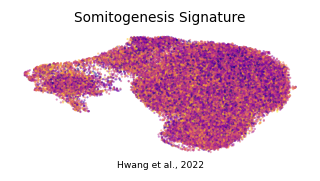

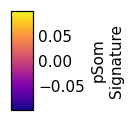

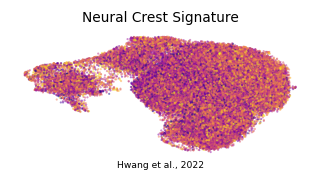

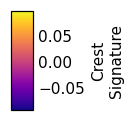

In [ ]:
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
fnmap  = {'Gast':'Gast_signature.pdf','pSom':'pSom_signature.pdf','Crest':'Crest_signature.pdf'}
xy = adata.obsm['X_umap']
for k in ['Gast','pSom','Crest']:
    v = adata.obs[k].values; lo, hi = np.percentile(v, [2, 98])
    fig, ax = plt.subplots(1, 1, figsize=(3.5, 1.5))
    sctr = ax.scatter(xy[:,0], xy[:,1], c=v, cmap='plasma', vmin=lo, vmax=hi, s=2,
                      alpha=0.5, linewidths=0, rasterized=True)
    ax.invert_yaxis(); ax.invert_xaxis(); ax.axis('off')
    ax.set_title(titles[k], size=9)
    ax.text(.5, -.08, 'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, fnmap[k]), bbox_inches='tight', dpi=200)
    # colorbar
    figc = plt.figure(figsize=(.66,1)); cax = figc.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(sctr, cax=cax); cb.ax.tick_params(size=0); cb.set_label(f'{k}\nSignature'); cb.solids.set_alpha(1)
    figc.savefig(os.path.join(pth_cb, f'{k}_colorbar.pdf'), bbox_inches='tight')
    print('saved', fnmap[k], '+ colorbar')

### Save `signatures.h5ad`

In [ ]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (63997, 19444)
